# Project 2 on Machine Learning: classification and regression, writing our own neural network code

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

**Note:** The solutions were developed collaboratively by Raji Nabih Youssef, Paula Solange Gund, and Elia Sundström.

**Deadline: November 9 (midnight), 2026.** Published October 6, 2026.

This notebook is the Jupyter version of the project text (`Project2.pdf`). The
code cells are *starting points*, not solutions: they set up the Runge data of
project 1 and show how to fetch the MNIST data for part e). Everything else is
yours to write.


# Solution part e):


In [1]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    # numpy-compatible functions that JAX can differentiate
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.datasets import load_digits
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.model_selection import learning_curve
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from sklearn.preprocessing import LabelBinarizer
from sklearn.linear_model import LogisticRegression


# Some functions from part a-d which are used in part e)

def sigmoid(z):     # sigmoid activation function
    return 1 / (1 + jnp.exp(-z))

def sigmoid_derivative(z):  # derivative of the sigmoid function
    p = sigmoid(z)
    return p*(1.0-p)

    
def ReLU(z):        # ReLU activation function
    return jnp.where(z > 0, z, 0.0)

def relu_derivative(z):     # derivative of the ReLU function
    return jnp.where(z > 0, 1.0, 0.0)

def leaky_relu(z, alpha=0.01):      # leaky ReLU activation function
    return jnp.where(z > 0, z, alpha * z)

def leaky_relu_derivative(z, alpha=0.01):
    return jnp.where(z > 0, 1.0, alpha)

def linear(z):          # linear activation function
    return z

def linear_derivative(z):       # derivative of the linear function
    return jnp.ones_like(z)

def softmax(z):         # softmax activation function
    shifted = z - jnp.max(z, axis=1, keepdims=True)
    e = jnp.exp(shifted)
    return e / jnp.sum(e, axis=1, keepdims=True)

def mse(predict, target):       # mean squared error loss function
    return jnp.mean((predict - target) ** 2)


def mse_gradient(prediction, target):       # gradient of the mean squared error loss function with respect to the predictions
    return 2 * (prediction - target) / target.size

def create_layers_batch(network_input_size, layer_output_sizes, rng):       # created layers for the neural network with specified input size and output sizes for each layer
    """week42tuesday.ipynb
     Network initialization : we Initialize weights from a normal distribution and biases b =  0.01
    """
    layers = []
    input_size = network_input_size
    for output_size in layer_output_sizes:
        W = jnp.asarray(rng.normal(0, 1 / np.sqrt(input_size), (input_size, output_size)))      #weights are initialized from a normal distribution with mean 0 and standard deviation 1/sqrt(input_size)
        b = jnp.zeros(output_size) + 0.01 # B = 0.01                                            #biases are initialized to 0.01
        layers.append((W, b))
        input_size = output_size
    return layers


def feed_forward_batch(inputs, layers, activation_funcs):           # feed forward propagation through the network for a batch of inputs
    """ from week42 tuesday """
    a = inputs
    for (W, b), activation in zip(layers, activation_funcs):        # for each layer, compute the weighted sum of inputs and biases, apply the activation function, and pass the result to the next layer
        a = activation(a @ W + b)
    return a


def feed_forward_saver_batch(inputs, layers, activation_funcs):     # feed forward propagation through the network for a batch of inputs, while saving the intermediate values for backpropagation
    """ from week42 tuesday: does forward propagation while saving  values for backpropagation.."""
    layer_inputs, zs = [], []
    a = inputs
    for (W, b), activation in zip(layers, activation_funcs):        # for each layer, compute the weighted sum of inputs and biases, apply the activation function, and pass the result to the next layer
        layer_inputs.append(a)
        z = a @ W + b                   # compute the weighted sum of inputs and biases
        a = activation(z)               # apply the activation function
        zs.append(z)
    return layer_inputs, zs, a


def backpropagation_batch(inputs, layers, activation_funcs, targets, activation_ders):
    """ from week42tuesday . calculate gradients of MSE with respect to weights and biases .
    """
    layer_inputs, zs, prediction = feed_forward_saver_batch(inputs, layers, activation_funcs)       # feed forward propagation while saving intermediate values for backpropagation
    layer_grads = [None] * len(layers)
    for i in reversed(range(len(layers))):                  # iterate over the layers in reverse order to compute gradients
        if i == len(layers) - 1:
            dC_da = mse_gradient(prediction, targets)
        else:
            W_next, _ = layers[i + 1]                       # get the weights of the next layer
            dC_da = dC_dz @ W_next.T                        # compute the gradient of the cost with respect to the activations of the current layer
            dC_dz = dC_da * activation_ders[i](zs[i])       # moved into the else block to avoid overwriting dC_dz for the last layer
        dC_dW = layer_inputs[i].T @ dC_dz                   # compute the gradient of the cost with respect to the weights of the current layer
        dC_db = jnp.sum(dC_dz, axis=0)                      # compute the gradient of the cost with respect to the biases of the current layer
        layer_grads[i] = (dC_dW, dC_db)
    return layer_grads

def optimiser_step(method, theta, gradient, state, step, rate):         # optimizer step for updating the weights and biases of the network using gradient descent, RMSprop, or Adam
    """
    from project 1,parameter updates using GD, RMSprop, and Adam.
    """
    if method == 'gd':
        return theta - rate * gradient, state
    if method == 'rmsprop':
        state['r'] = 0.99 * state.get('r', 0.0) + 0.01 * gradient**2
        return theta - rate * gradient / (jnp.sqrt(state['r']) + 1e-8), state
    if method == 'adam':
        state['m'] = 0.9 * state.get('m', 0.0) + 0.1 * gradient
        state['r'] = 0.999 * state.get('r', 0.0) + 0.001 * gradient**2
        m_hat = state['m'] / (1.0 - 0.9**step)
        r_hat = state['r'] / (1.0 - 0.999**step)
        return theta - rate * m_hat / (jnp.sqrt(r_hat) + 1e-8), state
    raise ValueError('Use gd, rmsprop or adam.')


def make_batches(n, batch_size, rng):       # creates mini-batches of indices for training the network. It shuffles the indices and divides them into batches of the specified size.
    indices = rng.permutation(n)
    return [indices[i:i + batch_size] for i in range(0, n, batch_size)]

# Shuffles observations and dividing  them into mini-batches(Mini batch training)

def train_network(layers, X, y, activation_funcs, activation_ders,                  # trains the neural network using backpropagation and the specified optimizer, learning rate, and number of epochs. It also tracks the best validation performance and returns the best model parameters.
                  optimizer, rate, epochs, X_validation=None, y_validation=None,
                  batch_size=32, seed=2026):
    
    X, y = jnp.asarray(X), jnp.asarray(y)
    if X_validation is not None:                # if validation data is provided, convert it to JAX arrays
        X_validation, y_validation = jnp.asarray(X_validation), jnp.asarray(y_validation)
    rng = np.random.default_rng(seed)
    states = [[{}, {}] for _ in layers]
    history = []
    best_validation = np.inf
    best_layers = [(W.copy(), b.copy()) for W, b in layers]
    best_epoch = 0
    step = 0
    for epoch in range(1, epochs + 1):                  # iterate over the number of epochs
        batches = [np.arange(len(X))] if optimizer == 'gd' else make_batches(len(X), batch_size, rng)
        for indices in batches:                         # iterate over the mini-batches of indices
            gradients = backpropagation_batch(X[indices], layers, activation_funcs,
                                               y[indices], activation_ders)
            step += 1
            for i, ((W, b), (dW, db)) in enumerate(zip(layers, gradients)):                     # update the weights and biases of each layer using the optimizer step
                W, states[i][0] = optimiser_step(optimizer, W, dW, states[i][0], step, rate)
                b, states[i][1] = optimiser_step(optimizer, b, db, states[i][1], step, rate)
                layers[i] = (W, b)
        if epoch % 20 == 0 or epoch == epochs:                                                  # Every 20 epochs  MSE , is recorded
            training_mse = float(mse(feed_forward_batch(X, layers, activation_funcs), y))       # compute the training MSE for the current epoch
            if X_validation is None:                                                            # if no validation data is provided, only record the training MSE and update the best model parameters if the training MSE is lower than the best validation MSE
                history.append((epoch, training_mse))
                best_layers = [(W.copy(), b.copy()) for W, b in layers]
                best_epoch = epoch
            else:
                validation_mse = float(mse(feed_forward_batch(X_validation, layers, activation_funcs), y_validation))   # compute the validation MSE for the current epoch
                history.append((epoch, training_mse, validation_mse))
                if validation_mse < best_validation:
                    best_validation = validation_mse
                    best_layers = [(W.copy(), b.copy()) for W, b in layers]
                    best_epoch = epoch
    return best_layers, np.asarray(history), best_epoch





### Part e): Classification analysis using neural networks

With a well-written code it should now be easy to change the activation function for the output layer.

Here we will change the cost function for our neural network code developed in parts b)–d) in order to perform a classification analysis (Section [8.11](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#classification-with-neural-networks) of the lecture notes). The classification problem we will study is the multiclass MNIST problem of handwritten digits (LeCun, Cortes and Burges), see the description of the data set at <https://www.tensorflow.org/datasets/catalog/mnist>. We will use the softmax cross entropy function discussed in a). In this project you should use the *full* MNIST data set ($70\,000$ images of $28\times 28$ pixels), the one used in the Monday lecture of week 41; the code of that lecture reads exactly the file described below. Note that the Tuesday session of week 41 (and Section [8.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#examples) of the lecture notes) uses the much smaller digits data set of Scikit-Learn (`load_digits`, $1797$ images of $8\times 8$ pixels, a different data set of the same kind and not a subset of MNIST). The reduced set is convenient for developing and debugging your code, since every run takes seconds, but the results you report should be for the full MNIST set.

The data set comes with a canonical split into $60\,000$ training images and $10\,000$ test images, each a $28\times 28$ array of grey-scale pixel values between 0 and 255. It can be downloaded, without registering anywhere, as a single NumPy archive (about 11 MB) from <https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz> and loaded with


In [2]:

with np.load("mnist.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]  # untouched until the end
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)
# (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


A feed-forward network takes a vector as input, so flatten each image to a vector of $784$ features and scale the pixel values to the interval $[0,1]$ (scaling makes a real difference for gradient descent, see Section 3.13 of the lecture notes),


In [3]:

x_train = x_train.reshape(len(x_train), -1) / 255.0
x_test = x_test.reshape(len(x_test), -1) / 255.0




Use the canonical split the way it is meant to be used: all training, model selection and tuning of hyperparameters (learning rate, penalty $\lambda$, number of layers and nodes, activation functions) is done on the training data only, for example by setting aside a validation set from the training data or by cross-validation (Chapter 3 of the lecture notes). The test set is used *once*, at the very end, to report the performance of the models you have selected. If you are limited by computing time, you may train on a subset of the training images, but evaluate on the full test set.

Remember to cite the data set in your report, as you would cite any other source; the citation is given on the data set page above (Y. LeCun, C. Cortes and C. J. C. Burges, *The MNIST database of handwritten digits*, <http://yann.lecun.com/exdb/mnist/>).

Feel free to suggest other data sets. If you find the classic MNIST data set somewhat limited, try the Fashion-MNIST data set of Zalando Research at <https://github.com/zalandoresearch/fashion-mnist>. It has exactly the same format and the same $60\,000/10\,000$ split, with ten classes of clothing items instead of digits, and the download links, loading code and the reference to cite are all on that page.

To measure the performance of our classification problem we will use the so-called *accuracy* score (Section 5.12 of the lecture notes). The accuracy is as you would expect just the number of correctly guessed targets $t_i$ divided by the total number of targets, that is

$$
\text{Accuracy} = \frac{\sum_{i=1}^n I(t_i = y_i)}{n} ,
$$

where $I$ is the indicator function, $1$ if $t_i = y_i$ and $0$ otherwise. Here $t_i$ represents the target and $y_i$ the outputs of your FFNN code and $n$ is simply the number of targets $t_i$.

Discuss your results and give a critical analysis of the various parameters, including hyperparameters like the learning rates and the regularization parameter $\lambda$, various activation functions, number of hidden layers and nodes and activation functions.

Again, we strongly recommend that you compare your own neural network code for classification and pertinent results against a similar code using **Scikit-Learn** or **TensorFlow/Keras** or **PyTorch** (see the paragraph on established libraries in Section [8.14](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#examples) of the lecture notes).

You should also compare your neural network results with those from logistic regression (Sections 5.3 and 5.6 of the lecture notes). Logistic regression is the *baseline* for the classification part: it is the classifier with no hidden layers, and a network with one or more hidden layers is only worth its extra cost if you can show that it performs better than this baseline. Your neural network code implements the equivalent of logistic regression by simply setting the number of hidden layers to zero and keeping just the input and the output layers (with the softmax activation and the cross entropy cost from part a)).

In addition to the accuracy, you should compute and interpret the *confusion matrix* of your best classification model (Section 5.12 of the lecture notes, see also <https://www.researchgate.net/figure/Confusion-matrix-of-MNIST-and-F-MNIST-embeddings_fig5_349758607>). The confusion matrix shows which digits are confused with which, something a single accuracy number hides, and if you also report the precision, the recall and the $F_1$ score, the confusion matrix is what makes these numbers interpretable. Scikit-Learn’s `confusion_matrix` and `ConfusionMatrixDisplay` from `sklearn.metrics` are convenient for this.

If you wish to compare with logistic regression from **Scikit-Learn** as well, the following code uses the flattened and scaled arrays from above


In [4]:

"""# Initialize the model (multinomial logistic regression with the saga solver)
model = LogisticRegression(solver='saga', max_iter=1000, random_state=42)
# Train the model
model.fit(x_train, y_train)
from sklearn.metrics import accuracy_score
# Make predictions on the test set
y_pred = model.predict(x_test)
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")"""

'# Initialize the model (multinomial logistic regression with the saga solver)\nmodel = LogisticRegression(solver=\'saga\', max_iter=1000, random_state=42)\n# Train the model\nmodel.fit(x_train, y_train)\nfrom sklearn.metrics import accuracy_score\n# Make predictions on the test set\ny_pred = model.predict(x_test)\n# Calculate accuracy\naccuracy = accuracy_score(y_test, y_pred)\nprint(f"Model Accuracy: {accuracy:.4f}")'

In [5]:
# define modified functions for classification tasks
def cross_entropy(prediction, target):
    '''cross entropy as defined in 3.1'''
    eps = 1e-12     # to avoid log(0) which is undefined
    prediction = jnp.clip(prediction, eps, 1.0)     # Clip predictions to avoid log(0)
    return -jnp.mean(jnp.sum(target * jnp.log(prediction), axis=1)) # return the mean cross-entropy loss over the batch

def backpropagation_batch_classification(inputs, layers, activation_funcs, targets, activation_ders, lmbd=0.0):
    """ base from week42tuesday. calculate gradients of cross entropy with respect to weights and biases .
    """
    layer_inputs, zs, prediction = feed_forward_saver_batch(inputs, layers, activation_funcs)       # forward propagation while saving values for backpropagation
    layer_grads = [None] * len(layers)
    batch_size = inputs.shape[0]
    for i in reversed(range(len(layers))):
        if i == len(layers) - 1:
            # From the derivative of the cross-entropy - see analytical expression above
            dC_dz = (prediction - targets) / batch_size    
        else:
            W_next, _ = layers[i + 1]                       
            dC_da = dC_dz @ W_next.T                       
            dC_dz = dC_da * activation_ders[i](zs[i])
        dC_dW = layer_inputs[i].T @ dC_dz + lmbd * layers[i][0]  # Add L2 regularization term
        dC_db = jnp.sum(dC_dz, axis=0)
        layer_grads[i] = (dC_dW, dC_db)         # Store the gradients for the current layer
    return layer_grads


def train_network_classification(layers, X, y, activation_funcs, activation_ders,               # trains the neural network for classification tasks using backpropagation and the specified optimizer, learning rate, and number of epochs. It also tracks the best validation performance and returns the best model parameters.
                  optimizer, rate, epochs, lmbd=0.0, X_validation=None, y_validation=None,
                  batch_size=32, seed=2026):
    '''Train a neural network for classification using mini-batch gradient descent and backpropagation.
    The function supports different optimizers (GD, RMSprop, Adam) and records the training and validation loss and accuracy at regular intervals.
    '''
    
    X, y = jnp.asarray(X), jnp.asarray(y)
    if X_validation is not None:                                # Convert validation data to JAX arrays if provided
        X_validation, y_validation = jnp.asarray(X_validation), jnp.asarray(y_validation)
    rng = np.random.default_rng(seed)
    states = [[{}, {}] for _ in layers]
    history = []
    best_validation = np.inf                                    # Initialize the best validation loss to infinity for comparison
    best_layers = [(W.copy(), b.copy()) for W, b in layers]     # Store the best layers (weights and biases) corresponding to the best validation loss
    best_epoch = 0
    step = 0
    for epoch in range(1, epochs + 1):                          # Loop over the number of epochs for training
        batches = [np.arange(len(X))] if optimizer == 'gd' else make_batches(len(X), batch_size, rng)
        for indices in batches:
            gradients = backpropagation_batch_classification(X[indices], layers, activation_funcs,      # calculate gradients of cross-entropy with respect to weights and biases
                                               y[indices], activation_ders, lmbd=lmbd)                         
            step += 1                                                                                   # increase the step count used for optimizer updates
            for i, ((W, b), (dW, db)) in enumerate(zip(layers, gradients)):
                W, states[i][0] = optimiser_step(optimizer, W, dW, states[i][0], step, rate)
                b, states[i][1] = optimiser_step(optimizer, b, db, states[i][1], step, rate)
                layers[i] = (W, b)
        if epoch % 20 == 0 or epoch == epochs:#
            # Evaluate training performance
            train_probabilities = feed_forward_batch(X, layers, activation_funcs)                                           # Predicted probabilities for the training set
            training_loss = float(cross_entropy(train_probabilities, y))                                                    # Training loss (cross-entropy) for the training set
            training_accuracy = float(jnp.mean(jnp.argmax(train_probabilities, axis=1) == jnp.argmax(y, axis=1)))           # Training accuracy for the training set; the sum of correct predictions divided by the total number of predictions
            if X_validation is None:
                history.append((epoch, training_loss, training_accuracy))                                                   # Record the training loss and accuracy in the history list
                best_layers = [(W.copy(), b.copy()) for W, b in layers]       
                best_epoch = epoch
            else:
                validation_probabilities = feed_forward_batch(X_validation, layers, activation_funcs)                       # Predicted probabilities for the validation set
                validation_loss = float(cross_entropy(validation_probabilities, y_validation))                              # Validation loss (cross-entropy) for the validation set
                validation_accuracy = float(accuracy_score(jnp.argmax(validation_probabilities, axis=1), jnp.argmax(y_validation, axis=1)))     # Validation accuracy for the validation set; the sum of correct predictions divided by the total number of predictions
                history.append((epoch, training_loss, training_accuracy, validation_loss, validation_accuracy))                                 # Record the training and validation loss and accuracy in the history list
                if validation_loss < best_validation:
                    best_validation = validation_loss
                    best_layers = [(W.copy(), b.copy()) for W, b in layers]
                    best_epoch = epoch
    return best_layers, np.asarray(history), best_epoch                                 # Return the best layers (weights and biases), the training history, and the epoch corresponding to the best validation loss

def baseline_logistic_regression(x_train, y_train, x_test, y_test):
    """Train a baseline logistic regression model and evaluate its accuracy on the test set."""
    # Using sklearn's LogisticRegression to establish a baseline for comparison with the neural network

    # Initialize the model (multinomial logistic regression with the saga solver)
    model = LogisticRegression(solver='saga', max_iter=1000, random_state=42)    
    # Train the model
    model.fit(x_train, y_train)
    # Make predictions on the test set
    y_pred = model.predict(x_test)
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    return model,accuracy

def evaluate_classifier(y_true, probabilities, model_name):         
    '''evaluate the classifier's performance using various metrics and display confusion matrix and ROC curves.'''
    y_pred = np.argmax(probabilities, axis=1)
    y_onehot = np.eye(10)[y_true]

    cm = sk_confusion_matrix(y_true, y_pred)                # confusion matrix: a table that is often used to describe the performance of a classification model on a set of test data for which the true values are known

    print(f"\n{model_name}")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")                                                   # accuracy: defined as the ratio of correct predictions to total predictions
    print(f"Precision: {precision_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")             # precision: defined as the ratio of true positives to the sum of true positives and false positives
    print(f"Recall:    {recall_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")                # recall: defined as the ratio of true positives to the sum of true positives and false negatives
    print(f"F1 score:  {f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")                    # F1 score: defined as the harmonic mean of precision and recall. The relative contribution of precision and recall to the F1 score are equal. 
    print(f"ROC-AUC:   {roc_auc_score(y_onehot, probabilities, multi_class='ovr', average='weighted'):.4f}")    # ROC-AUC: defined as the area under the ROC curve
    print(sk_classification_report(y_true, y_pred, zero_division=0))                                            # classification report: provides a detailed summary of the precision, recall, F1 score, and support for each class in the classification task

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay(                                 # display the confusion matrix using sklearn's ConfusionMatrixDisplay
        confusion_matrix=cm,
        display_labels=np.arange(10)
    ).plot(ax=ax, colorbar=False)

    #ax.set_title(f"{model_name}: confusion matrix")
    plt.tight_layout()
    plt.savefig(f"{model_name}_confusion_matrix.pdf", dpi=300)
    plt.show()




class NeuralNetClassifier(BaseEstimator, ClassifierMixin):
    """
    A neural network classifier for multi-class classification tasks.
    This class implements a feedforward neural network with customizable architecture, activation functions, and training parameters
    
    LLM-assisted. Tool: GitHub Copilot (october 2026), role: helped with fixing some error messages
    """   

    def __init__(self, hidden=(64,), activation="relu", gamma=0.1, lmbd=0.0, epochs=20, batch_size=100, seed=2026):     # initialize the neural network classifier with the specified parameters
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y):                        # Fit the neural network classifier to the training data.
            # Validate the input data
        X, y = check_X_y(X, y)

        # Store the class labels
        self.classes_ = np.unique(y)            
        n_classes = len(self.classes_)

        # Encode integer labels as one-hot vectors
        self.label_binarizer_ = LabelBinarizer()
        y_encoded = self.label_binarizer_.fit_transform(y)

        # LabelBinarizer returns a single column for binary classification.
        # Expand it to two columns if necessary.
        if n_classes == 2:
            y_encoded = np.column_stack(
                [1 - y_encoded[:, 0], y_encoded[:, 0]]
            )

        # Select activation functions
        if self.activation == "relu":
            activation_func = ReLU
            activation_der = relu_derivative
        elif self.activation == "sigmoid":
            activation_func = sigmoid
            activation_der = sigmoid_derivative
        elif self.activation == "leaky_relu":
            activation_func = leaky_relu
            activation_der = leaky_relu_derivative
        else:
            raise ValueError(
                "activation must be 'relu', 'sigmoid', or 'leaky_relu'"
            )

        # Initialize the network
        self.layers_ = create_layers_batch(
            X.shape[1],
            list(self.hidden) + [n_classes],
            np.random.default_rng(self.seed)
        )

        # Set up the activation functions for each layer
        activation_funcs = (
            [activation_func] * len(self.hidden) + [softmax]
        )
        activation_ders = (
            [activation_der] * len(self.hidden) + [linear_derivative]
        )

        # Train the network
        self.layers_, self.history_, self.best_epoch_ = (
            train_network_classification(
                self.layers_,
                X,
                y_encoded,
                activation_funcs,
                activation_ders,
                optimizer="adam",
                rate=self.gamma,
                epochs=self.epochs,
                batch_size=self.batch_size,
                seed=self.seed
            )
        )

        # Store the activation functions for prediction
        self.activation_funcs_ = activation_funcs

        return self

    def predict_proba(self, X):
        check_is_fitted(self, ["layers_", "activation_funcs_", "classes_"])
        X = check_array(X)

        # Calculate the probability of each class
        probabilities = feed_forward_batch(
            X,
            self.layers_,
            self.activation_funcs_)
        return np.asarray(probabilities)
    
    def predict(self, X):
        probabilities = self.predict_proba(X)

        # Convert the predicted class indices to the original labels
        return self.classes_[np.argmax(probabilities, axis=1)]




In [6]:

# Your code for part e) here
# The whole dataset
# LLM-assisted. Tool: GitHub Copilot (october 2026), role: suggested use of jnp.eye(10)[...], fixed some errors in code
with np.load("mnist.npz") as data:
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]  # untouched until the end. Has 20% of the data for testing

x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0
x_train = x_train.reshape(len(x_train), -1)
x_test = x_test.reshape(len(x_test), -1)

colors = ["tab:blue", "tab:orange", "tab:green"]
plt.rcParams.update({
    "font.size": 12,          # Default text size
    "axes.labelsize": 16,     # Axis labels
    "axes.titlesize": 16,     # Plot title
    "xtick.labelsize": 12,    # X-axis tick labels
    "ytick.labelsize": 12,    # Y-axis tick labels
    "legend.fontsize": 12    # Legend

})


Hidden units: (32,) | Learning rate: 0.00 | CV accuracy: 0.9255 ± 0.0021 | Training accuracy: 0.9711
Hidden units: (64,) | Learning rate: 0.00 | CV accuracy: 0.9357 ± 0.0036 | Training accuracy: 0.9872
Hidden units: (128,) | Learning rate: 0.00 | CV accuracy: 0.9450 ± 0.0028 | Training accuracy: 0.9973
Hidden units: (32, 32) | Learning rate: 0.00 | CV accuracy: 0.9249 ± 0.0028 | Training accuracy: 0.9792
Hidden units: (64, 64) | Learning rate: 0.00 | CV accuracy: 0.9415 ± 0.0023 | Training accuracy: 0.9966
Hidden units: (32,) | Learning rate: 0.01 | CV accuracy: 0.9394 ± 0.0034 | Training accuracy: 0.9970
Hidden units: (64,) | Learning rate: 0.01 | CV accuracy: 0.9434 ± 0.0035 | Training accuracy: 0.9919
Hidden units: (128,) | Learning rate: 0.01 | CV accuracy: 0.9514 ± 0.0049 | Training accuracy: 0.9969
Hidden units: (32, 32) | Learning rate: 0.01 | CV accuracy: 0.9317 ± 0.0013 | Training accuracy: 0.9899
Hidden units: (64, 64) | Learning rate: 0.01 | CV accuracy: 0.9404 ± 0.0028 | Tr

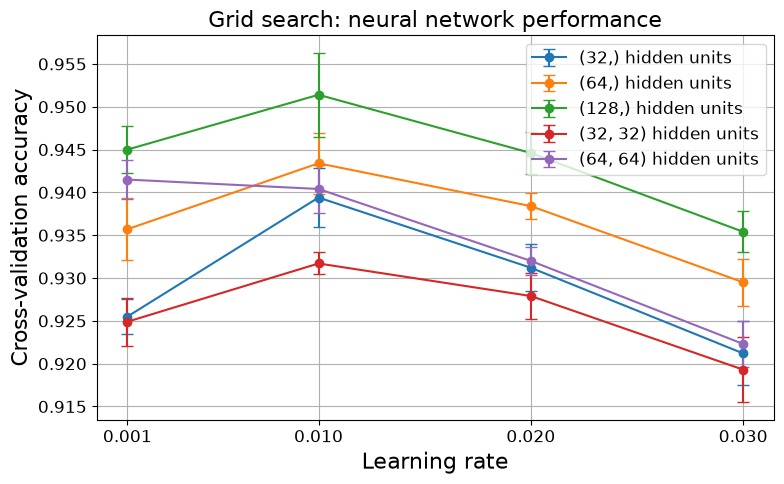

In [7]:
rng = np.random.default_rng(2026)
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])       # Select 1000 samples from each class (0-9) for a total of 10,000 samples
X_sub, y_sub = x_train[sub], y_train[sub]

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)                 # StratifiedKFold ensures that each fold of the cross-validation has the same proportion of classes as the original dataset

hidden_units = [(32,), (64,), (128,), (32, 32), (64, 64)]
learning_rates = [0.001, 0.01, 0.02, 0.03]
#activation="sigmoid"
activation="relu"
#activation="leaky_relu"

search = GridSearchCV(NeuralNetClassifier(activation=activation), {"hidden": hidden_units, "gamma": learning_rates}, cv=cv_strat, scoring="accuracy", return_train_score=True, n_jobs=1)    # cross validation with 5 folds, scoring based on accuracy, and using a single core for computation

search.fit(X_sub, y_sub)            # Fit the model using grid search to find the best combination of hidden units and learning rates based on cross-validation accuracy

results = search.cv_results_        # Store the results of the grid search

for i, params in enumerate(results["params"]):          # Loop through each combination of hyperparameters

    mean_acc = results["mean_test_score"][i]
    std_acc = results["std_test_score"][i]
    se_acc = std_acc / np.sqrt(5)

    train_acc = results["mean_train_score"][i]

    print(
        f"Hidden units: {params['hidden']} | "
        f"Learning rate: {params['gamma']:.2f} | "
        f"CV accuracy: {mean_acc:.4f} ± {se_acc:.4f} | "
        f"Training accuracy: {train_acc:.4f}"
    )

results = search.cv_results_

# LLM-assisted. Tool: GitHub Copilot (october 2026), role: suggested plotting code for activation functions comparison
# plotting the results of the grid search
plt.figure(figsize=(8, 5))

for hidden in hidden_units:
    means = []
    errors = []

    for i, params in enumerate(results["params"]):
        if params["hidden"] == hidden:
            means.append(results["mean_test_score"][i])
            errors.append(results["std_test_score"][i] / np.sqrt(5))

    plt.errorbar(
        learning_rates,
        means,
        yerr=errors,
        marker="o",
        capsize=4,
        label=f"{hidden} hidden units"
    )

plt.xlabel("Learning rate")
plt.ylabel("Cross-validation accuracy")
plt.title("Grid search: neural network performance")
plt.xticks(learning_rates)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("grid_search_results.pdf", dpi=300)
plt.show()


#relu:          Hidden units: (128,) | Learning rate: 0.01 | CV accuracy: 0.9507 ± 0.0039 | Training accuracy: 0.9956
#sigmoid:       Hidden units: (128,) | Learning rate: 0.01 | CV accuracy: 0.9506 ± 0.0022 | Training accuracy: 1.0000
#leaky relu:    Hidden units: (128,) | Learning rate: 0.01 | CV accuracy: 0.9539 ± 0.0027 | Training accuracy: 0.9972


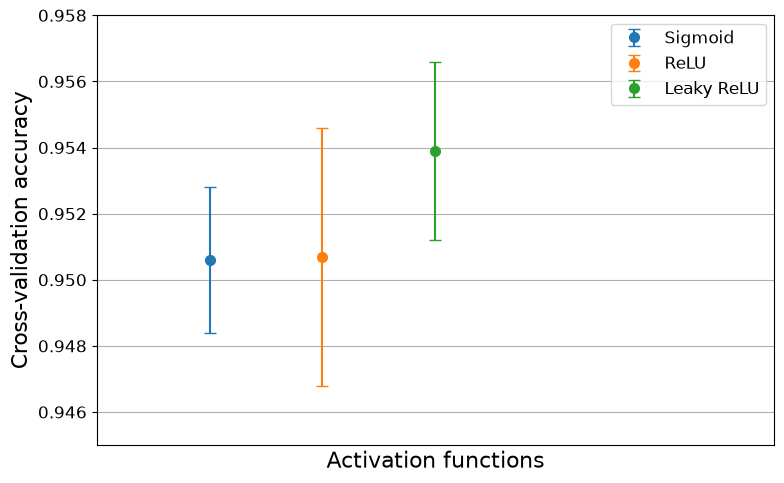

In [8]:
activation_functions = ["Sigmoid", "ReLU", "Leaky ReLU"]

cv_accuracy = [0.9506, 0.9507, 0.9539]
cv_error = [0.0022, 0.0039, 0.0027]

x = np.array([0.05, 0.1, 0.15])

# LLM-assisted. Tool: GitHub Copilot (october 2026), role: suggested plotting code for activation functions comparison
plt.figure(figsize=(8, 5))

for i in range(3):
    plt.errorbar(
        x[i],
        cv_accuracy[i],
        yerr=cv_error[i],
        marker="o",
        markersize=7,
        capsize=4,
        color=colors[i],
        linestyle="none",
        label=activation_functions[i]
    )

plt.ylabel("Cross-validation accuracy")
plt.xlabel("Activation functions")
plt.xticks([])
plt.ylim(0.945, 0.958)
plt.xlim(0, 0.3)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("activation_functions.pdf", dpi=300)
plt.show()


The best accuracy is for leaky ReLU with $128$ hidden neurons at a learning rate of $0.01$ with the accuracy $0.9539 \pm 0.0027$. 

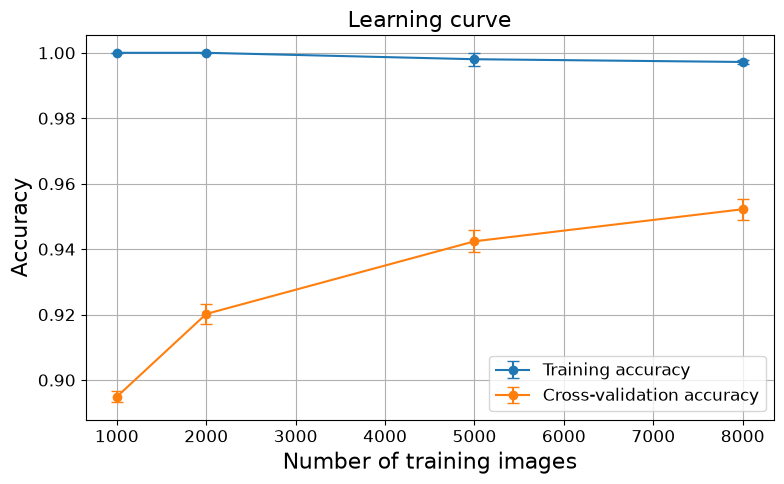

<Figure size 640x480 with 0 Axes>

In [9]:
train_sizes = [1000, 2000, 5000, 8000]              # Define the training sizes for the learning curve analysis. These sizes represent the number of training samples used to train the model at each step of the learning curve.
best = search.best_estimator_
sizes, train_scores, cv_scores = learning_curve(
    best,
    X_sub,
    y_sub,
    train_sizes=train_sizes,
    cv=cv_strat,
    scoring="accuracy",
    shuffle=True,
    random_state=2026,
    n_jobs=1
)

# Mean and standard error across the five folds
train_mean = np.mean(train_scores, axis=1)
cv_mean = np.mean(cv_scores, axis=1)

# Standard error of the mean (SEM) is calculated as the standard deviation divided by the square root of the number of samples
train_se = np.std(train_scores, axis=1, ddof=1) / np.sqrt(5)
cv_se = np.std(cv_scores, axis=1, ddof=1) / np.sqrt(5)

# LLM-assisted. Tool: GitHub Copilot (November 2026), role: suggested plotting code for learning curve
# Plot
plt.figure(figsize=(8, 5))

plt.errorbar(
    sizes, train_mean, yerr=train_se,
    marker="o", capsize=4, label="Training accuracy"
)

plt.errorbar(
    sizes, cv_mean, yerr=cv_se,
    marker="o", capsize=4, label="Cross-validation accuracy"
)

plt.xlabel("Number of training images")
plt.ylabel("Accuracy")
plt.title("Learning curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
plt.savefig("learning_curve.pdf", dpi=300)

we chose ReLU with the learning rate $0.01$ and $128$ hidden nodes because the error margins overlap and ReLU gives a better accuracy

(45000, 784) (45000, 10)
Best epoch: 20
Neural Network training accuracy: 0.9924
Neural Network test accuracy:      0.9693

Neural Network
Accuracy:  0.9693
Precision: 0.9693
Recall:    0.9693
F1 score:  0.9693
ROC-AUC:   0.9988
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.98      0.99      0.98      1135
           2       0.97      0.96      0.96      1032
           3       0.97      0.97      0.97      1010
           4       0.95      0.98      0.96       982
           5       0.97      0.96      0.97       892
           6       0.98      0.97      0.98       958
           7       0.97      0.97      0.97      1028
           8       0.96      0.96      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



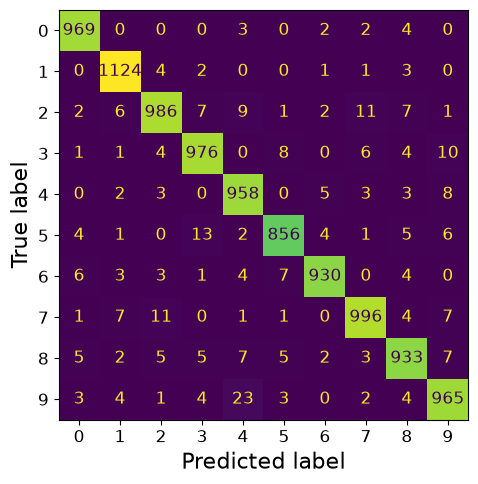

In [10]:


X_fit, X_val, y_fit, y_val = train_test_split(      # divide the training data into fitting and validation sets, the validation set is used to tune hyperparameters and prevent overfitting, while the fitting set is used to train the model
    x_train,
    y_train,
    test_size=0.25,
    random_state=2026,
    stratify=y_train
)

Y_fit = jnp.eye(10)[y_fit]  # one-hot encoding of the fitting labels
Y_val = jnp.eye(10)[y_val]  # one-hot encoding of the validation labels

print(X_fit.shape, Y_fit.shape)
# Expected input and output shapes: (45000, 784) (45000, 10) because 60,000 * 0.75 = 45,000 and 10 classes for one-hot encoding and 784 features



layers = create_layers_batch(784, [128, 10], np.random.default_rng(2026))  # 784 input features, one hidden layers with 128 nodes, and 10 output classes
activation_funcs = [ReLU, softmax]  # ReLU for hidden layers, softmax for output layer
activation_ders = [relu_derivative, None]  # Derivatives for hidden layers, None for output layer (softmax derivative is handled in backpropagation)

best_layers, history, best_epoch = train_network_classification(        # train the neural network classifier using the fitting data, activation functions, and backpropagation with cross-entropy loss. The best model parameters are returned based on validation performance.
    layers=layers,
    X=X_fit,
    y=Y_fit,
    activation_funcs=activation_funcs,          # activation functions for each layer
    activation_ders=activation_ders,            # derivatives for each layer
    optimizer="adam",                           # optimizer for weight updates. Alternatives: "adam", "rmsprop", "gd"
    rate=0.01,                                 # learning rate for the optimizer
    lmbd=0,                                     # L2 regularization parameter. Tested values: 0, 0.00001, 0.0001, 0.001, 0.01
    epochs=23,                                 # number of training epochs 
    X_validation=X_val,                         # validation inputs
    y_validation=Y_val,                         # validation targets
    batch_size=64,    
    seed=2026
)

print("Best epoch:", best_epoch)

# training accuracy
p_train_nn = np.asarray(
    feed_forward_batch(X_fit, best_layers, activation_funcs)
)
y_pred_train_nn = np.argmax(p_train_nn, axis=1)
training_accuracy = accuracy_score(y_fit, y_pred_train_nn)
print(f"Neural Network training accuracy: {training_accuracy:.4f}")


# Evaluate the final neural network on the unseen test set
p_test_nn = np.asarray(
    feed_forward_batch(jnp.asarray(x_test), best_layers, activation_funcs)
)

y_pred_nn = np.argmax(p_test_nn, axis=1)
accuracy_nn = accuracy_score(y_test, y_pred_nn)


# test accuracy
print(f"Neural Network test accuracy:      {accuracy_nn:.4f}")

# Evaluate NN model using the unseen test data and plot confusion matrix
evaluate_classifier(y_test, p_test_nn, "Neural Network")


#gamma = 0.01
#for batch_size=64, 
#for lmbd = 0:
#Logistic Regression test accuracy: 0.9253

#leaky ReLU: Neural Network test accuracy:      0.9647
#ReLU: Neural Network test accuracy:      0.9683

#for batch_size=32:
#Neural Network test accuracy:      0.9598

#gamma = 0.001
#Neural Network test accuracy:      0.9768


#regularization parameters:         (training acc., test acc.)
#lambda = 0 ->          NN accuracy (0.9877, 0.9683)
#lambda = 0.00001 ->    NN accuracy (0.9866, 0.9658)
#lambda = 0.0001 ->     NN accuracy (0.9754, 0.9679)
#lambda = 0.001 ->      NN accuracy (0.9524, 0.9487)
#lambda = 0.01 ->       NN accuracy (0.9056, 0.9070)


In [ ]:
#logistic regression
model, baseline_accuracy = baseline_logistic_regression(X_fit, y_fit, X_val, y_val)
#Evaluate logistic regression on the same test set
p_test_logistic = model.predict_proba(x_test)

y_pred_logistic = model.predict(x_test)

# Evaluate logistic regression on training data
y_pred_train_logistic = model.predict(X_fit)
accuracy_train_logistic = accuracy_score(y_fit, y_pred_train_logistic)

print(f"Logistic Regression training accuracy: {accuracy_train_logistic:.4f}")

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
# test accuracy
print(f"Logistic Regression test accuracy: {accuracy_logistic:.4f}")
# Evaluate logistic regression model using the unseen test data and plot confusion matrix
evaluate_classifier(y_test, p_test_logistic, "Logistic Regression")

Logistic Regression training accuracy: 0.9399


The best epoch between $0-200$ is at $20$, therefore anything above it is unnecessary. Accuracy was $0.9797$ with batch size 32.

### Part f): Critical evaluation of the various algorithms

After all these glorious calculations, you should now summarize the various algorithms and come with a critical evaluation of their pros and cons. Which algorithm works best for the regression case and which is best for the classification case? Section [8.15](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#limitations-and-a-top-down-view) of the lecture notes gives a top-down view of what neural networks can and cannot do that you may find useful here. These codes can also be part of your final project 3, but now applied to other data sets.


In [ ]:
# Your code for part f) here

## Summary of methods to implement and analyze

**Required implementation:**

1.  Reuse the regression code and results from project 1; these will act as a benchmark for seeing how suited a neural network is for this regression task.

2.  Implement a neural network with

    - a flexible number of layers;

    - a flexible number of nodes in each layer;

    - a changeable activation function in each layer (Sigmoid, ReLU, Leaky ReLU, as well as linear and softmax);

    - a changeable cost function, which will be set to the MSE for regression and the cross entropy for multiclass classification;

    - an optional $L_1$ or $L_2$ norm of the weights and biases in the cost function (only used for computing gradients, not as interpretable metrics).

3.  Implement the back propagation algorithm to compute the gradient of your neural network.

4.  Reuse the implementation of plain and stochastic gradient descent from project 1 (and adapt the code to work with your neural network)

    - with no optimization algorithm;

    - with RMSprop;

    - with Adam.

5.  Implement logistic regression as the baseline classification model (equivalent to a neural network with just the output layer, that is with zero hidden layers).

6.  Implement scaling and train-test splitting of your data, preferably using Scikit-Learn (MNIST comes with its own test set; tune on the training data and use the test set only for the final evaluation).

7.  Implement and compute metrics like the MSE, the accuracy and the confusion matrix.

**Required analysis:**

1.  Briefly show and argue for the advantages and disadvantages of the methods from project 1.

2.  Explore and show the impact of changing the number of layers, nodes per layer, choice of activation function, and inclusion of $L_1$ and $L_2$ norms. Present only the most interesting results from this exploration. 2D heat maps will be good for this: start with finding a well performing set of hyperparameters, then change two at a time in a range that shows good and bad performance.

3.  Show and argue for the advantages and disadvantages of using a neural network for regression on your data.

4.  Show and argue for the advantages and disadvantages of using a neural network for classification on your data. In particular, show whether and why a network with hidden layers performs better than the logistic-regression baseline (no hidden layers).

5.  Compute and interpret a confusion matrix of your best classification model (Section 5.12 of the lecture notes and <https://www.researchgate.net/figure/Confusion-matrix-of-MNIST-and-F-MNIST-embeddings_fig5_349758607>).

6.  Show and argue for the advantages and disadvantages of the different gradient methods and learning rates when training the neural network.


## Background literature

- The lecture notes of the course, in particular Chapter 8 (neural networks, at <https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html>), Chapter 4 (stochastic gradient descent, RMSprop, Adam and automatic differentiation) and Chapter 5 (the cross entropy, the softmax function and how to measure the quality of a classifier).

- The text of Michael Nielsen is highly recommended, see Nielsen’s book at <http://neuralnetworksanddeeplearning.com/>. It is an excellent read.

- Goodfellow, Bengio and Courville, Deep Learning, at <https://www.deeplearningbook.org/>. Here we recommend chapters 6, 7 and 8.

- Raschka et al. at <https://sebastianraschka.com/blog/2022/ml-pytorch-book.html>. Here we recommend chapters 11, 12 and 13.


## Introduction to numerical projects

Here follows a brief recipe and recommendation on how to answer the various questions when preparing your answers.

- Give a short description of the nature of the problem and the eventual numerical methods you have used.

- Describe the algorithm you have used and/or developed. Here you may find it convenient to use pseudocoding. In many cases you can describe the algorithm in the program itself.

- Include the source code of your program. Comment your program properly. You should have the code at your GitHub/GitLab link. You can also place the code in an appendix of your report.

- If possible, try to find analytic solutions, or known limits in order to test your program when developing the code. In this project the gradient from automatic differentiation and the closed-form OLS solution of project 1 are exactly such tests for your neural network code.

- Include your results either in figure form or in a table. Remember to label your results. All tables and figures should have relevant captions and labels on the axes.

- Try to evaluate the reliability and numerical stability/precision of your results. If possible, include a qualitative and/or quantitative discussion of the numerical stability, eventual loss of precision etc.

- Try to give an interpretation of your results in your answers to the problems.

- Critique: if possible include your comments and reflections about the exercise, whether you felt you learnt something, ideas for improvements and other thoughts you’ve made when solving the exercise. We wish to keep this course at the interactive level and your comments can help us improve it.

- Try to establish a practice where you log your work at the computer lab. You may find such a logbook very handy at later stages in your work, especially when you don’t properly remember what a previous test version of your program did. Here you could also record the time spent on solving the exercise, various algorithms you may have tested or other topics which you feel worthy of mentioning.


## Format for electronic delivery of report and programs

The preferred format for the report is a PDF file. You can also use DOC or postscript formats or an IPython notebook file. As programming language we prefer that you choose between C/C++, Fortran2008, Julia or Python. The following prescription should be followed when preparing the report:

- Use Canvas to hand in your projects, log in at <https://www.uio.no/english/services/it/education/canvas/> with your normal UiO username and password.

- Upload **only** the report file or the link to your GitHub/GitLab or similar type of repository! For the source code file(s) you have developed please provide us with your link to your GitHub/GitLab or similar domain. The report file should include all of your discussions and a list of the codes you have developed. Do not include library files which are available at the course homepage, unless you have made specific changes to them.

- In your GitHub/GitLab or similar repository, please include a folder which contains selected results. These can be in the form of output from your code for a selected set of runs and input parameters.

Finally, we encourage you to collaborate. Optimal working groups consist of 2–3 students. You can then hand in a common report.


## Software and needed installations

If you have Python installed (we recommend Python 3) and you feel pretty familiar with installing different packages, we recommend that you install the following Python packages via `pip` as

> `pip install numpy scipy matplotlib ipython jupyter scikit-learn`  
> `pip install pandas seaborn`  
> `pip install jax jaxlib`

(`autograd` is a lighter alternative to JAX if you want to check your back propagation code against automatic differentiation; PyTorch or TensorFlow are needed only if you choose them for the comparison with an established library). For Python 3, replace `pip` with `pip3` where needed.

For OSX users we recommend also, after having installed Xcode, to install `brew`. Brew allows for a seamless installation of additional software via for example `brew install python3`. For Linux users, with its variety of distributions like for example the widely popular Ubuntu distribution, you can use `pip` as well and simply install Python as `sudo apt-get install python3` etc.

If you don’t want to install various Python packages with their dependencies separately, we recommend [Anaconda](https://docs.anaconda.com/), an open source distribution of the Python and R programming languages for large-scale data processing, predictive analytics, and scientific computing, that aims to simplify package management and deployment. Package versions are managed by the package management system `conda`.

Popular software packages written in Python for ML are [Scikit-learn](http://scikit-learn.org/stable/), [JAX](https://jax.readthedocs.io), [TensorFlow](https://www.tensorflow.org/), [PyTorch](http://pytorch.org/) and [Keras](https://keras.io/). These are all freely available at their respective GitHub sites. They encompass communities of developers in the thousands or more, and the number of code developers and contributors keeps increasing.
